In [1]:
#%pip install xgboost # Uncomment if running in a fresh environment

In [2]:
# NAME: Bruce Bai 
#GITHUB HANDLE: bruceb002 
# STUDENT ID: 1563103829 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree, _tree
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import KNNImputer
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import xgboost as xgb

1b) ORIGINAL DECISION TREE


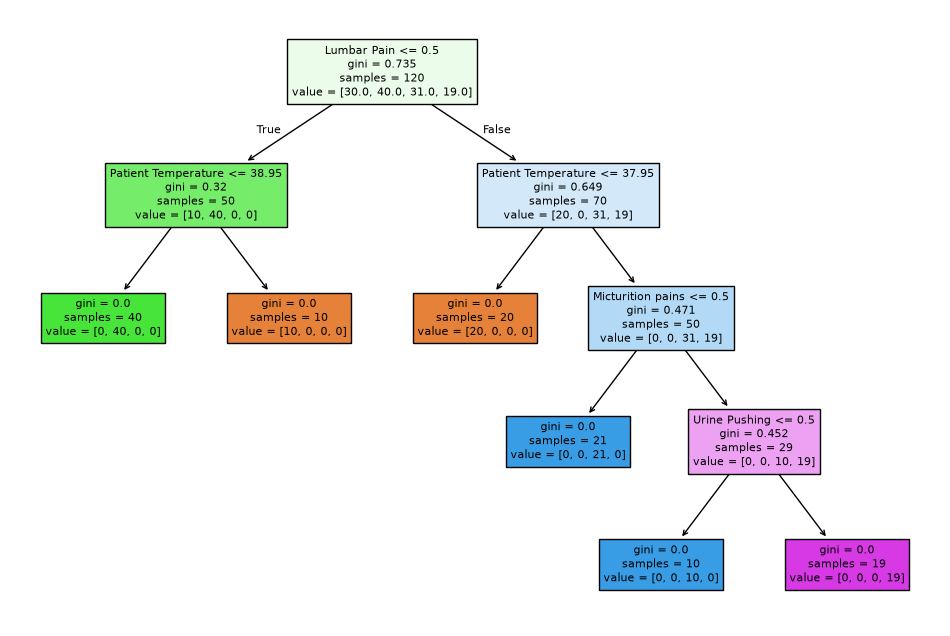

1c) IF-THEN RULES

def tree(Patient Temperature, Nausea, Lumbar Pain, Urine Pushing, Micturition pains, Burning Urethra and Itchy swelling Uretha Outlet):
  if Lumbar Pain <= 0.5:
    if Patient Temperature <= 38.95000076293945:
      return "Bladder inflammation only"
    else:  # if Patient Temperature > 38.95000076293945
      return "Neither condition"
  else:  # if Lumbar Pain > 0.5
    if Patient Temperature <= 37.95000076293945:
      return "Neither condition"
    else:  # if Patient Temperature > 37.95000076293945
      if Micturition pains <= 0.5:
        return "Nephritis only"
      else:  # if Micturition pains > 0.5
        if Urine Pushing <= 0.5:
          return "Nephritis only"
        else:  # if Urine Pushing > 0.5
          return "Both conditions"


1d) COST-COMPLEXITY PRUNING

Finding Alpha accuracy scores:

    Alpha: 0.000000, Nodes: 11, CV Accuracy: 0.975000
    Alpha: 0.098167, Nodes: 7, CV Accuracy: 0.908333
    Alpha: 0.133333, Nodes: 5, CV Accuracy: 0.7333

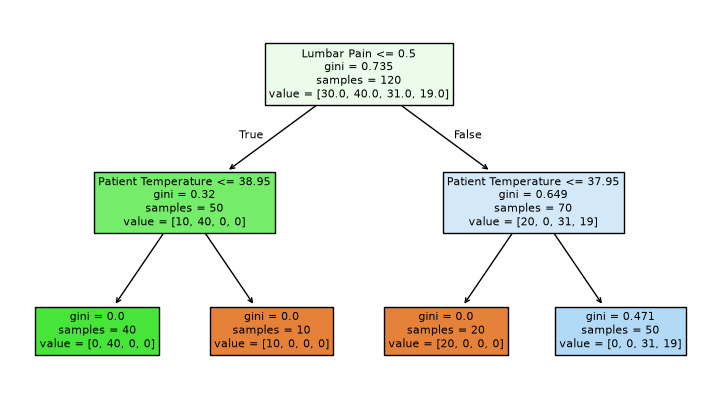

If-Then rules for pruned subtree:

def tree(Patient Temperature, Nausea, Lumbar Pain, Urine Pushing, Micturition pains, Burning Urethra and Itchy swelling Uretha Outlet):
  if Lumbar Pain <= 0.5:
    if Patient Temperature <= 38.95000076293945:
      return "Bladder inflammation only"
    else:  # if Patient Temperature > 38.95000076293945
      return "Neither condition"
  else:  # if Lumbar Pain > 0.5
    if Patient Temperature <= 37.95000076293945:
      return "Neither condition"
    else:  # if Patient Temperature > 37.95000076293945
      return "Nephritis only"

Analysis:

    Using shuffled 6-fold stratified cross-validation, the original 11-node tree achieved the highest accuracy of 97.50% at alpha = 0. Pruning to 7 nodes (alpha ≈ 0.09817) reduced accuracy to 90.83%, while further pruning to 5 nodes reduced accuracy to 73.33%. Although the 7-node subtree provides a simpler set of decision rules, it also merges classes 2 and 3 into one of the leaves, preventing the fitted subtr

In [3]:
#1a) Obtain dataset
col_names = ["Patient Temperature", "Nausea", "Lumbar Pain", "Urine Pushing", "Micturition pains", \
             "Burning Urethra and Itchy swelling Uretha Outlet", "Urinary Bladder Inflammation", "Nephritis of Renal Pelvis Origin"]

# Per pandas.read_csv official documentation and debugging
df = pd.read_csv("../data/diagnosis.data", sep='\t', names=col_names, decimal=",", encoding="utf-16")

# 1b) Build Decision Tree
for col in df:
    if col != "Patient Temperature":
        df[col] = (df[col]=="yes").astype(int)
        
def determine_multiclass_label(row):
    bladder_infection = row["Urinary Bladder Inflammation"]
    nephritis = row["Nephritis of Renal Pelvis Origin"]

    if not (bladder_infection or nephritis):
        return 0
    elif bladder_infection and not nephritis:
        return 1
    elif not bladder_infection and nephritis:
        return 2
    else:
        return 3
        
df["Multiclass Label"] = df.apply(determine_multiclass_label, axis=1)

X = df.drop(columns=["Urinary Bladder Inflammation", "Nephritis of Renal Pelvis Origin", "Multiclass Label"])
y = df["Multiclass Label"]

clf = DecisionTreeClassifier(random_state=1313)
clf.fit(X, y)

print("1b) ORIGINAL DECISION TREE")
plt.figure(figsize=(12, 8))
plot_tree(clf, feature_names=X.columns, filled=True)
plt.show()

# 1c) Convert to If-Then rules, per footnote advice

powerset_labels = {0: "Neither condition", 1: "Bladder inflammation only", 2: "Nephritis only", 3: "Both conditions"}

def tree_to_code(tree, feature_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    print("def tree({}):".format(", ".join(feature_names)))

    def recurse(node, depth):
        indent = "  " * depth
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            print("{}if {} <= {}:".format(indent, name, threshold))
            recurse(tree_.children_left[node], depth + 1)
            print("{}else:  # if {} > {}".format(indent, name, threshold))
            recurse(tree_.children_right[node], depth + 1)
        else:
            class_index = tree_.value[node][0].argmax()
            prediction = tree.classes_[class_index]
            print('{}return "{}"'.format(indent, powerset_labels[prediction]))

    recurse(0, 1)

print("1c) IF-THEN RULES\n")
tree_to_code(clf, list(X.columns))
print("\n")

# 1d) Cost Complexity Pruning (Based on the official scikit learn documentation)
print("1d) COST-COMPLEXITY PRUNING\n")
print("Finding Alpha accuracy scores:\n")

path = clf.cost_complexity_pruning_path(X, y)
ccp_alphas = path.ccp_alphas

results = []
cv = StratifiedKFold(n_splits=6, shuffle=True, random_state=1313)

for alpha in ccp_alphas:
    tree_model = DecisionTreeClassifier(random_state=1313, ccp_alpha=alpha)
    scores = cross_val_score(tree_model, X, y, cv=cv)
    tree_model.fit(X, y)

    accuracy = scores.mean()
    nodes = tree_model.tree_.node_count
    results.append((alpha, accuracy, nodes))

    print(f"    Alpha: {alpha:.6f}, Nodes: {nodes}, CV Accuracy: {accuracy:.6f}")

# Select the highest accuracy model, preferring fewer nodes in case of a tie
best_alpha, best_accuracy, best_nodes = results[0]

for alpha, accuracy, nodes in results:
    if accuracy > best_accuracy or (accuracy == best_accuracy and nodes < best_nodes):
        best_alpha, best_accuracy, best_nodes = alpha, accuracy, nodes

print("\nBest Alpha:", best_alpha)
print("Best CV Accuracy:", best_accuracy)
print("Selected Tree Nodes:", best_nodes)

# Pruning with the 7-node subtree (Sub-Optimal, Pruned, Subtree)
chosen_alpha, pruned_accuracy, pruned_nodes = results[1]

pruned_subtree = DecisionTreeClassifier(random_state=1313, ccp_alpha=chosen_alpha)
pruned_subtree.fit(X, y)

print("\n7-Node Pruned Subtree:")
plt.figure(figsize=(9, 5))
plot_tree(pruned_subtree, feature_names=X.columns, filled=True)
plt.show()

print("If-Then rules for pruned subtree:\n")
tree_to_code(pruned_subtree, list(X.columns))

# Compare shuffled and non-shuffled cross-validation
cv_unshuffled = StratifiedKFold(n_splits=6, shuffle=False)

original_tree = DecisionTreeClassifier(random_state=1313)
original_unshuffled = cross_val_score(original_tree, X, y, cv=cv_unshuffled).mean()

pruned_tree = DecisionTreeClassifier(random_state=1313, ccp_alpha=chosen_alpha)
pruned_unshuffled = cross_val_score(pruned_tree, X, y, cv=cv_unshuffled).mean()

print("\nAnalysis:\n")
print("    Using shuffled 6-fold stratified cross-validation, the original 11-node tree achieved the highest accuracy of 97.50% at alpha = 0. \
Pruning to 7 nodes (alpha ≈ 0.09817) reduced accuracy to 90.83%, while further pruning to 5 nodes reduced accuracy to 73.33%. Although \
the 7-node subtree provides a simpler set of decision rules, it also merges classes 2 and 3 into one of the leaves, preventing the fitted \
subtree from distinguishing nephritis alone from both conditions occurring together. Therefore, the original tree remains the preferred \
model based on cross-validation accuracy and its ability to distinguish all four classes, while the 7-node subtree demonstrates the \
trade-off between simplicity and predictive performance.\n")
print(f"    Interestingly, non-shuffled cross-validation produced accuracies of {original_unshuffled:.4%} and {pruned_unshuffled:.4%} \
for the original and 7-node trees, respectively, compared to {best_accuracy:.4%} and {pruned_accuracy:.4%} with shuffling. This \
suggests that the dataset's original ordering affected how observations were distributed across validation folds. Shuffling changed \
the fold composition while preserving class proportions, producing noticeably different accuracy estimates. This highlights the \
sensitivity of cross-validation results to the data splitting strategy.\n")

2c) CORRELATION MATRIX: (122 x 122 FEATURES)


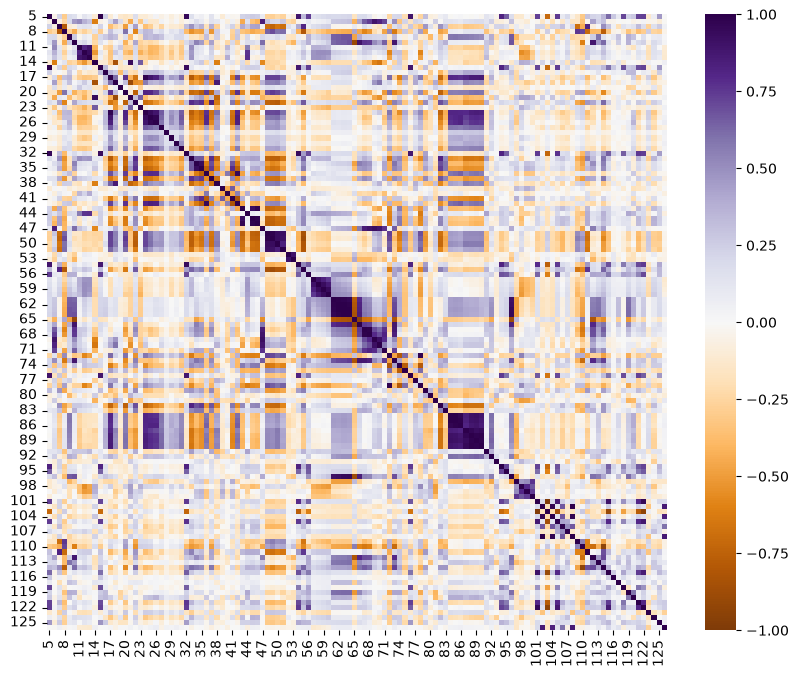

2d) CV FOR 122 FEATURES

 [2.20350254 0.3532983  1.4109204  0.32378156 1.35916219 1.61427779
 0.36583987 0.29069289 0.49516051 0.42344171 2.00174364 0.63884887
 0.57975339 0.32771006 0.70003012 0.35923995 0.36851263 0.6990305
 0.34963908 0.52773189 0.54563343 0.50755219 0.589469   0.80968509
 0.60619385 0.6707979  0.47395972 2.30496971 0.75398017 0.67560022
 0.52828627 0.57840084 0.5561328  0.34732725 0.51058034 0.39822568
 0.50846131 0.42210586 0.39558337 0.40381162 0.3592727  0.37146815
 0.31695475 0.33061114 0.33247588 0.32942584 0.32855095 0.33624845
 0.33272212 2.99419645 0.91980289 2.90049716 0.68420109 0.58489027
 0.50490986 0.45566604 1.3001003  1.29763181 1.28123297 1.28403377
 0.28867317 1.4590666  0.73453473 0.75710873 0.36691384 0.31940729
 0.46845379 0.35031616 1.12719959 0.34837064 0.81088779 1.95877973
 0.26964697 0.33754097 1.06474242 0.43611899 0.47041143 0.91821097
 0.84874387 0.84788021 0.87874984 0.87473297 0.63318641 0.56188436
 0.58701424 0.55559247 0.34582952 0.4

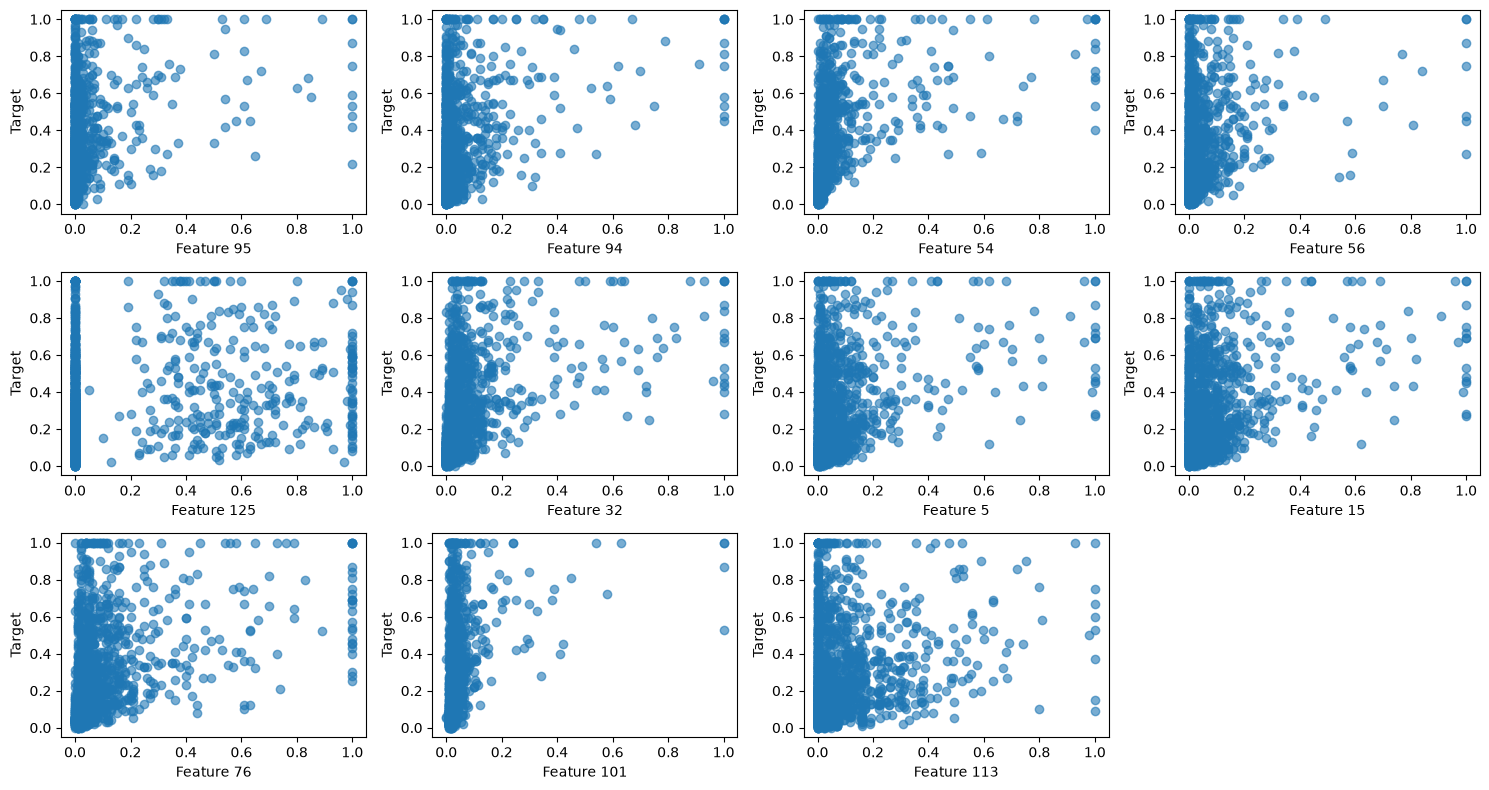

Conclusion Analysis:

    Since part 2c) already examined correlations between features, I chose to plot the 11 highest CV features against the target to examine their individual relationships with the crime rate. From these scatter plots, we cannot confidently conclude that these features are significant predictors. Most feature values are clustered near zero, while their corresponding crime rates still vary considerably, showing no clear linear relationship for most features. However, these plots only examine one feature at a time and don't account for the effects of other predictors. Therefore, further multivariate regression analysis is needed to better evaluate their predictive importance.

Box Plots: 


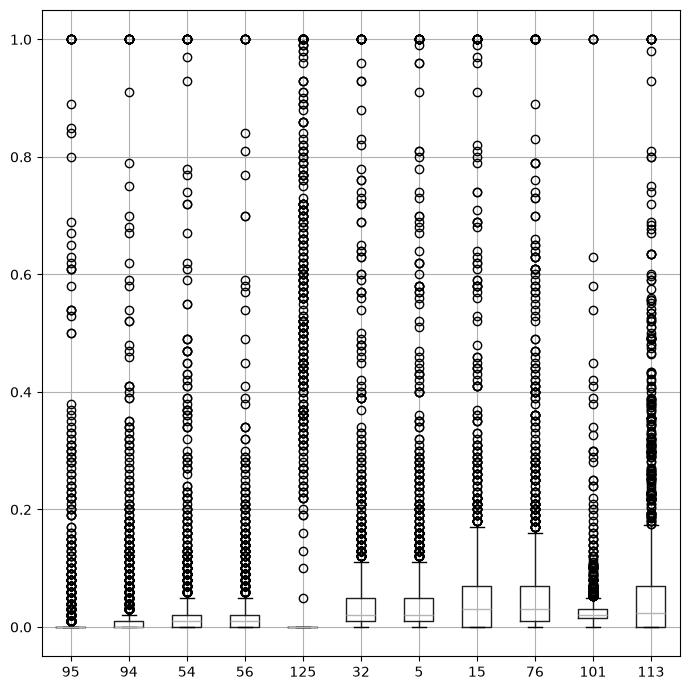

In [4]:
# 2a) & 2b) Download and Cleanse communities.data
df = pd.read_csv("../data/communities.data", header=None)
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X = X.drop(columns=[0, 1, 2, 3, 4]) # The non-predictive Columns are the first five
X = X.replace('?', np.nan).astype(float) # According to Official Spec, it's better to ensure np.nan type

X_train_raw, X_test_raw = X.iloc[:1495], X.iloc[1495:]
y_train, y_test = y.iloc[:1495], y.iloc[1495:]

imputer = KNNImputer(n_neighbors=5) # Data Imputation by KNN seems like a fit approach
X_train = imputer.fit_transform(X_train_raw)
X_test = imputer.transform(X_test_raw)

cleaned_up_X = np.concatenate([X_train, X_test], axis=0)

#2c) Plotting Correlation matrix
matrix = pd.DataFrame(cleaned_up_X, columns=X.columns).corr()
print("2c) CORRELATION MATRIX: (122 x 122 FEATURES)")
plt.figure(figsize=(10, 8))
sns.heatmap(matrix, cmap='PuOr', annot=False, vmin=-1, vmax=1, center=0)
plt.show()

# 2d) Calculating the CV
s = cleaned_up_X.std(axis=0, ddof=1)
m = cleaned_up_X.mean(axis=0)
CV = s / m
print("2d) CV FOR 122 FEATURES\n\n", CV, "\n")

# 2e) Making Scatter and Box Plots for top floor(sqrt(128)) = 11 features
print("2e) PLOTTING HIGHEST CV FEATURES\n")
print("Scatter Plots: ")
labelled_CVs = pd.Series(CV, index=X.columns)
sorted_CVs = labelled_CVs.sort_values(ascending=False)
highest_CVs = sorted_CVs.nlargest(11)
top_cols = highest_CVs.index
selected = pd.DataFrame(cleaned_up_X, columns=X.columns)[top_cols]

fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for axis, col in zip(axes.flat, top_cols):
    axis.scatter(selected[col], y, alpha=0.6)
    axis.set_xlabel(f'Feature {col}')
    axis.set_ylabel('Target')

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

print("Conclusion Analysis:\n")
print("    Since part 2c) already examined correlations between features, I chose to plot the 11 highest CV features against the \
target to examine their individual relationships with the crime rate. From these scatter plots, we cannot confidently conclude that \
these features are significant predictors. Most feature values are clustered near zero, while their corresponding crime rates still \
vary considerably, showing no clear linear relationship for most features. However, these plots only examine one feature at a time \
and don't account for the effects of other predictors. Therefore, further multivariate regression analysis is needed to better \
evaluate their predictive importance.\n")

print("Box Plots: ")
fig, axes = plt.subplots(figsize=(7, 7))
selected.boxplot()
plt.tight_layout()
plt.show()
print("")

In [5]:
# 2f) Fitting via Least Squares Linear Regression
print("2f) PERFORMORANCE OF LEAST SQUARES LINEAR REGRESSION\n")
lr_model = linear_model.LinearRegression()
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)
mse_value = mean_squared_error(y_test, y_pred)
print(f"The test error for linear regression and least squares is: {mse_value:.6}. This provides our \
baseline performance metric before evaluating the ridge regression model, or the other alternatives (ie. LASSO, PCR, BOOSTING).\n")

# 2g) Fitting via Ridge Regression & Cross-Validation
print("2g) PERFORMORANCE OF RIDGE REGRESSION AND CROSS-VALIDATION")
model = make_pipeline(KNNImputer(n_neighbors=5), Ridge())
alphas = np.logspace(-3, 4, 15)
grid = GridSearchCV(model, {'ridge__alpha': alphas}, cv=5, scoring='neg_mean_squared_error') 
grid.fit(X_train_raw, y_train)
y_pred = grid.predict(X_test_raw)
ridge_test_mse = mean_squared_error(y_test, y_pred)

print("Best alpha:", f"{grid.best_params_['ridge__alpha']:.6}", " || ", f"Ridge Test MSE: {ridge_test_mse:.6f}\n")
print(f"Compared to ordinary least squares (MSE ≈ {mse_value:.6}), Ridge Regression achieved a slightly lower test MSE of \
{ridge_test_mse:.6}. By shrinking coefficients toward zero rather than completely removing predictors, Ridge can reduce their \
individual influence while still allowing them to contribute to predictions. This may be useful when multiple correlated features \
each contain some predictive information. However, the improvement in test error was relatively small.\n")

# 2h) LASSO model Performance
alphas = np.logspace(-5, 0, 21)

def fit_lasso(standardize):
    if not standardize:
        pipeline = make_pipeline(KNNImputer(n_neighbors=5), Lasso(max_iter=10000))
    else:
        pipeline = make_pipeline(KNNImputer(n_neighbors=5), StandardScaler(), Lasso(max_iter=10000))

    grid = GridSearchCV(pipeline, {'lasso__alpha': alphas}, cv=5, scoring='neg_mean_squared_error')
    grid.fit(X_train_raw, y_train)

    y_pred = grid.predict(X_test_raw)
    mse = mean_squared_error(y_test, y_pred)
    
    lasso_model = grid.best_estimator_.named_steps['lasso']
    coefs = lasso_model.coef_
    
    selected = []
    for col, coef in zip(X_train_raw.columns, coefs):
        if coef != 0:
            selected.append(col)

    return grid, mse, selected

# Unstandardized Features
grid_unscaled, mse_unscaled, selected_unscaled = fit_lasso(standardize=False)

print("2h) LASSO MODEL: UNSTANDARDIZED VS STANDARDIZED")
print("Unstandardized Best Alpha:", grid_unscaled.best_params_['lasso__alpha'], " || ", "Unstandardized Test MSE:", mse_unscaled)
print(f"The {len(selected_unscaled)} selected features' indices:", list(selected_unscaled))

# Standardized Features
grid_scaled, mse_scaled, selected_scaled = fit_lasso(standardize=True)

print("\nStandardized Best Alpha:", grid_scaled.best_params_['lasso__alpha'], " || ", "Standardized Test MSE:", mse_scaled)
print(f"The {len(selected_scaled)} selected features' indicies:", list(selected_scaled), "\n")

print("The unstandardized LASSO model selected 76 of 122 features (alpha=0.0001, test MSE=0.017528), while the standardized model \
selected 75 (alpha=0.000562, test MSE=0.017554). Both performed very similarly to OLS (MSE=0.017539), despite removing 46-47 features. \
This suggests that some removed features may contain overlapping or limited additional predictive information. Ridge performed slightly \
better (MSE=0.017313), possibly because it shrinks coefficients without completely eliminating potentially useful predictors. Although \
the dataset was already normalized, standardization changed which features LASSO selected, but had very little effect on its \
predictive performance.")

2f) PERFORMORANCE OF LEAST SQUARES LINEAR REGRESSION

The test error for linear regression and least squares is: 0.0175387. This provides our baseline performance metric before evaluating the ridge regression model, or the other alternatives (ie. LASSO, PCR, BOOSTING).

2g) PERFORMORANCE OF RIDGE REGRESSION AND CROSS-VALIDATION
Best alpha: 3.16228  ||  Ridge Test MSE: 0.017313

Compared to ordinary least squares (MSE ≈ 0.0175387), Ridge Regression achieved a slightly lower test MSE of 0.0173134. By shrinking coefficients toward zero rather than completely removing predictors, Ridge can reduce their individual influence while still allowing them to contribute to predictions. This may be useful when multiple correlated features each contain some predictive information. However, the improvement in test error was relatively small.

2h) LASSO MODEL: UNSTANDARDIZED VS STANDARDIZED
Unstandardized Best Alpha: 0.0001  ||  Unstandardized Test MSE: 0.01752828723108147
The 76 selected features' in

In [6]:
# 2i) PCR Model Performance
print("2i) PCR MODEL PERFORMANCE")
pcr_pipeline = make_pipeline(KNNImputer(n_neighbors=5), StandardScaler(), PCA(), LinearRegression())

components = range(90, 111)

grid_pcr = GridSearchCV(pcr_pipeline, {'pca__n_components': components}, cv=5, scoring='neg_mean_squared_error')
grid_pcr.fit(X_train_raw, y_train)

y_pred_pcr = grid_pcr.predict(X_test_raw)
mse_pcr = mean_squared_error(y_test, y_pred_pcr)

print("Best M:", grid_pcr.best_params_['pca__n_components'])
print(f"PCR Test MSE: {mse_pcr:.6}", "\n")
print(f"We initially used 5-fold cross-validation to test a broad range of principal component counts, from very few components up to \
all 122. Since the initial search favored values around M=100, we refined the search to M=90 through M=110. Cross-validation then \
selected M=94, resulting in a test MSE of {mse_pcr:.6}. This was slightly higher than the errors obtained from OLS, Ridge, and LASSO. \
Unlike Ridge and LASSO, which regularize feature coefficients, PCR reduces dimensionality based on feature variance rather than \
predictive importance. Therefore, it may have discarded lower-variance components that still contained useful information for \
predicting crime rates.\n")

# 2j) Boosting!
print("2j) BOOSTING TREE PERFORMANCE")
xgb_pipeline = make_pipeline(KNNImputer(n_neighbors=5), xgb.XGBRegressor(objective='reg:squarederror', random_state=1313))

xgb_alphas = [0] + list(np.logspace(-3, 2, 11))

grid_xgb = GridSearchCV(xgb_pipeline, {'xgbregressor__reg_alpha': xgb_alphas}, cv=5, scoring='neg_mean_squared_error')

grid_xgb.fit(X_train_raw, y_train)

y_pred_xgb = grid_xgb.predict(X_test_raw)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)

best_alpha = grid_xgb.best_params_['xgbregressor__reg_alpha']
print("Best alpha:", best_alpha)
print(f"XGBoost Test MSE: {mse_xgb:.6f}", "\n")
print(f"Using 5-fold cross-validation, XGBoost selected an optimal L1 regularization parameter of alpha={best_alpha}, resulting in a \
test MSE of {mse_xgb:.6}, the highest among the models tested. Ridge performed best (MSE={ridge_test_mse:.6}), while OLS and both \
LASSO models performed similarly (MSE around 0.0175), and PCR also slightly outperformed XGBoost (MSE={mse_pcr:.6}). This suggests \
that the linear models may have already captured much of the predictive information without needing XGBoost's additional complexity. \
Unlike LASSO, XGBoost's L1 regularization penalizes tree leaf weights rather than directly eliminating predictors, so its weaker \
performance does not necessarily reflect losing useful features. However, since we only tuned the L1 regularization parameter, other \
XGBoost configurations may perform better. Overall, increasing model complexity did not necessarily improve predictive performance.")

2i) PCR MODEL PERFORMANCE
Best M: 94
PCR Test MSE: 0.018047 

We initially used 5-fold cross-validation to test a broad range of principal component counts, from very few components up to all 122. Since the initial search favored values around M=100, we refined the search to M=90 through M=110. Cross-validation then selected M=94, resulting in a test MSE of 0.018047. This was slightly higher than the errors obtained from OLS, Ridge, and LASSO. Unlike Ridge and LASSO, which regularize feature coefficients, PCR reduces dimensionality based on feature variance rather than predictive importance. Therefore, it may have discarded lower-variance components that still contained useful information for predicting crime rates.

2j) BOOSTING TREE PERFORMANCE
Best alpha: 1.0
XGBoost Test MSE: 0.018243 

Using 5-fold cross-validation, XGBoost selected an optimal L1 regularization parameter of alpha=1.0, resulting in a test MSE of 0.0182434, the highest among the models tested. Ridge performed best (

### Appendix / Acknowledgment: Generative AI Assistance

“Assistance with debugging, hyperparameter tuning strategies (StratifiedKFold), and multi-model performance analysis for machine learning pipeline” prompt. *Gemini*, Google, Oct. 2026, gemini.google.com.

In compliance with course policies regarding the educational use of Large Language Models, Google Gemini was utilized as a technical collaborator during the development of this assignment. Specifically, AI assistance was employed for three core functions:

* **Code Debugging & Refactoring:** Reviewing base code for logical inconsistencies, resolving syntax or structural bugs, and optimizing code readability.
* **Hyperparameter Tuning & Validation Strategy:** Troubleshooting convergence behavior and refining cross-validation strategies, including the integration of `StratifiedKFold` to stabilize hyperparameter search (such as regularization paths and cost-complexity pruning alphas).
* **Output Interpretation & Synthesis:** Assisting in the qualitative interpretation of complex multi-model comparisons and high-dimensional visual patterns to build a holistic understanding of model behavior.

All foundational analysis, code execution, environment verification, and final written content were independently reviewed, executed, and synthesized by the author.